In [1]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import glob
import os
import cmath 
import json
import seaborn as sns
from collections import Counter
import scipy as sp
from scipy.stats import linregress

import PyQt5
# %matplotlib qt
import mne
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from tqdm import tqdm

# **Data Loading & Variables**

In [2]:

SW = 2 # smoothing window size (in seconds)

fname = 1
detrend_order = 1 # idk 
pen_param = 500
kfold = 10

SUBJS = ["07", "09", "11", "12"]

tmin = -0.2
tmax = 1.5

condition_list = ["presented_angles", "expected_angles_deg"]
condition = "expected_angles_deg"

# futur code à mettre en place : 
subj_rot_simu = {
    "07" : [+45, -45], 
}
# à adapter avec les données des fit 

In [3]:
device_list = ["macbook", "iMac"]
device = "macbook"

subject = "12"


if device == "iMac" :
        derivative_root = f'/Volumes/My Passport/Data/derivatives/mne-bids-pipeline/sub-{subject}/meg/' 

elif device == "macbook" :
        derivative_root = f'/Users/elodiehusson/Desktop/Projet/Tâche MEG/data MEG (preprocessed)/données MEG preprocessed/'


# **Functions**

In [5]:
## FUNCTION 

def get_timearray(SW, tmin, tmax):
    """when smoothing window applied, the time array might be shifted to the right.
    """
    
    
    times = epochs.times
    if SW > 1:
        times = times - (times[-1] - times[-2]) * SW / 2
    idx_zero = np.abs(times - 0).argmin()
    idx_tmin = np.abs(times - tmin).argmin()
    idx_tmax = np.abs(times - tmax).argmin()
    times = times[int(SW) - 1:]
    return(times)


def fisher_z_transform(r):
    """ apply fisher transformation to avoid non normal data. Since the correlation values are between -1 and 1,
    the fisher transformation is applied to make the data more normal and to allow for better statistical analysis
    
    r is the pearson correlation value
    """
    r = np.array(r)
    return 0.5 * np.log((1 + r) / (1 - r))

def moving_average(x, w):
    return np.convolve(x, np.ones(w)/w, 'valid')



def read_sub(savename, SW):
    """ read the results of the decoding and apply a moving average to smooth the results. 
    The moving average is applied to the predicted values of the decoding, and the true values are not smoothed. 
    The function returns the true values, the smoothed predicted values, and the test ids if they are present in the data.
    """
    
    dat = pd.read_pickle(savename)
    y_pred = np.stack(dat['y_pred'].to_numpy()) 
    y_true = dat['y_test'].to_numpy()[0]
    y_pred_avg = np.array([moving_average(y_pred[:, i], SW) for i in range(len(y_true))])
    if 'test_id' in dat.columns:
        test_id =  np.stack(dat['test_id'].to_numpy())
        return(y_true, y_pred_avg, test_id[0])
    else:
        return(y_true, y_pred_avg)
    
    
def open_decodingresults(savename, SW):
    """ 
    """
    output=[]
    alldat = []
    y_true, y_pred_avg, *_ = read_sub(savename, SW)
    alldat.append([sp.stats.pearsonr(y_true, y_pred_avg[:,i])[0] for i in range(np.shape(y_pred_avg)[1])])
    output.append(fisher_z_transform(alldat))
    return(output)



def Temporal_RidgeDecoding(Data,Y,indexes,pen_param,kfold):
    '''
    :param Data: MEG data to decode from
    :param Y: Value to predict
    :param indexes: index position of the trials
    :param pen_param: penalization parameter for the ridge regression
    :param kfold: number of folds

    Function to compute the Temporal decoding with ridge regression of variable 'Y' from MEG data 'Data'
    For reproducibility the seed is set to 42.
    '''

    corr = []
    y_predsave = []
    y_testsave = []
    res = pd.DataFrame()  # Declare variable
    kf = KFold(n_splits=kfold, shuffle=True, random_state=42)
    test_id = []
    
    # defining the index for each kfold for the train and test data
    for train_index, test_index in kf.split(Data[:, :, 0]):
        test_id = [*test_id, *indexes[test_index]]
        
    for i in tqdm(range(np.shape(Data)[2])): # progression bar for each time point # à remettre pour avoir tous les points
        
    # if llm == 9 :
    #     times = epochs.times
    #     i = np.abs(times - 0.2).argmin()

        X = Data[:, :, i]
        # kf = KFold(n_splits=kfold, shuffle=True, random_state=42)
        corr_fold = []
        y_pred_fold = []
        y_test_fold = []
        for train_index, test_index in kf.split(X):
            X_train, X_test = X[train_index], X[test_index]  # Train data for this fold from the indices decided earlier
            y_train, y_test = Y[train_index], Y[test_index]  # Test data for this fold from the indices decided earlier
            
            reg = make_pipeline(StandardScaler(with_mean=False), Ridge(alpha=pen_param,)) # definition of the regression
            reg.fit(X_train, y_train)     # Train, apply the regression on the train dataset
            y_pred = reg.predict(X_test)  # Test, predict with test dataset
            
            corr_fold.append(sp.stats.pearsonr(y_test, y_pred)[0])  # Append pearson corr results
            y_pred_fold  = [*y_pred_fold, *y_pred]
            y_test_fold = [*y_test_fold, *y_test]
        
        y_predsave.append(np.array(y_pred_fold).flatten())
        y_testsave.append(np.array(y_test_fold).flatten())
        corr.append(np.mean(corr_fold))
    res['corr'] = corr
    res['y_pred'] = y_predsave
    res['y_test'] = y_testsave
    res['test_id'] = [test_id for i in range(np.shape(Data)[2])] # à remettre pour avoir tous les temps 
    # res['test_id'] = [test_id]
    return(res)



def get_data_epochs (subject) : 
    # epochs loading 
    
    if device == "iMac" :
        epochs = mne.read_epochs(f'/Volumes/My Passport/Data/derivatives/mne-bids-pipeline/sub-{subject}/meg/sub-{subject}_task-FRINT_proc-clean_epo.fif', preload=True,verbose=False)

    elif device == "macbook" :
        epochs = mne.read_epochs( derivative_root + f'sub-{subject}/sub-{subject}_task-FRINT_proc-clean_epo.fif', preload=True,verbose=False)
        metadata_file = pd.read_csv(f"/Users/elodiehusson/Desktop/Projet/Tâche MEG/Data comportement/metadata_for_epochs/FRINT_MEG_S{subject}_cleaned_metadata.csv")


    epochs.get_data().shape
    print("\nThere are \nn_trial = {} epochs, \nn_channels = {} channels, \nn_times = {} time points".format(*epochs.get_data().shape))

    ## metadata loading
    epochs.metadata = epochs.metadata.drop(columns = ["Stim/S1", "Stim/S2", "Stim/S3", "Stim/S4", "Stim/S5", "Stim/S6", "Stim/S7", "SeqStart", "BlockStart", "Resp", "RespProb"])
    epochs.metadata = pd.concat([epochs.metadata, metadata_file], axis = 1)
    epochs.metadata["expected_angles_deg"] = np.rad2deg(epochs.metadata["expected_angles"])
    

   
    #### PREPARE DATA (X) AND VARIABLE TO PREDICT (Y)
    # detrending the epochs to remove the linear trend from the data, which can be caused by slow drifts in the signal or changes in the baseline.
    epochs.apply_function(mne.filter.detrend, picks="meg", order=detrend_order)

    # applying the hilbert transform to transform the data into complex representation
    # by doing this, we double the number of features
    epochs = epochs.copy().apply_hilbert(envelope=False)
    Data = epochs.get_data()  # Get data
    real_part = np.real(Data) # amplitude of original data
    imag_part = np.imag(Data) # phase of the data
    Data = np.concatenate((real_part, imag_part), axis=1) 
    
    return Data, epochs.metadata
    

def get_cos_sin_index (condition, subject) :
    Data, Metadata = get_data_epochs(subject)
    Angle  = ((np.array(Metadata[condition])%180)/180)*np.pi
    Y_cos = np.abs((Angle%np.pi) - np.pi / 2)
    Y_sin = np.abs(((Angle+np.pi/4) % np.pi)-np.pi/2)
    indexes = Metadata.index
    
    return Angle, Y_cos, Y_sin, indexes, Data, Metadata

    


# **Prepare Data**

In [27]:
# Creation of the target variable (Y)
Angle, Y_cos, Y_sin, indexes, Data, Metadata = get_cos_sin_index(condition, subject)
print("After detrending and hilbert transform, there are \nn_trial = {} epochs, \nn_channels = {} channels, \nn_times = {} time points".format(*Data.shape))


There are 
n_trial = 1440 epochs, 
n_channels = 328 channels, 
n_times = 426 time points
Replacing existing metadata with 2 columns
Replacing existing metadata with 9 columns
After detrending and hilbert transform, there are 
n_trial = 1440 epochs, 
n_channels = 656 channels, 
n_times = 426 time points


# **Call decoding and save**

In [ ]:
####### CALL DECODING AND SAVE

for cond in condition_list : 
    for sub in SUBJS : 
        Angle, Y_cos, Y_sin, indexes, Data, Metadata = get_cos_sin_index(cond, sub)
        
        Temporal_RidgeDecoding(Data,Y_cos,indexes,pen_param,kfold).to_pickle(
            derivative_root + f"sub-{sub}/" + f'{cond}_Cos_{sub}' + '.pkl')
        Temporal_RidgeDecoding(Data,Y_sin,indexes,pen_param,kfold).to_pickle(
            derivative_root + f"sub-{sub}/" + f'{cond}_Sin_{sub}' + '.pkl') 



# Temporal_RidgeDecoding(Data,Y_cos,indexes,pen_param,kfold).to_pickle(derivative_root + f"sub-{sub}/" + f'{condition}_Cos_{sub}' + '.pkl')
# Temporal_RidgeDecoding(Data,Y_sin,indexes,pen_param,kfold).to_pickle(derivative_root + f"sub-{sub}/" + f'{condition}_Sin_{sub}' + '.pkl')

 


There are 
n_trial = 1440 epochs, 
n_channels = 328 channels, 
n_times = 426 time points
Replacing existing metadata with 2 columns
Replacing existing metadata with 9 columns


to run only epochs that are like +45 only, or just 0° etc 

In [ ]:
# # indexes : 


# ## rotations vs no rotation
# indexes_rotation_stimulus = metadata_file[metadata_file["rotation_in_degrees"]!= 0.0].index
# indexes_NO_rotation_stimulus = metadata_file[metadata_file["rotation_in_degrees"]== 0.0].index

# ## colors 
# indexes_blue = metadata_file[metadata_file["stim_color"]== "blue"].index
# indexes_red = metadata_file[metadata_file["stim_color"]== "red"].index
# indexes_green = metadata_file[metadata_file["stim_color"]== "green"].index

# ## element number

# # indexes_e1 = metadata_file[metadata_file["?"]  != 0.0].index
# # indexes_e2 = metadata_file[metadata_file["?"]  != 0.0].index
# # indexes_e3 = metadata_file[metadata_file["?"]  != 0.0].index
# # indexes_e4 = metadata_file[metadata_file["?"]  != 0.0].index
# # indexes_e5 = metadata_file[metadata_file["?"]  != 0.0].index
# # indexes_e6 = metadata_file[metadata_file["?"]  != 0.0].index
# # indexes_e7 = metadata_file[metadata_file["?"]  != 0.0].index


# indexes_list = {
#     "indexes_rotation_stimulus" : indexes_rotation_stimulus , 
#     "indexes_NO_rotation_stimulus" : indexes_NO_rotation_stimulus, 
#     "indexes_blue" : indexes_blue,
#     "indexes_red" : indexes_red,
#     "indexes_green" : indexes_green, 
#     # "indexes_e1" : indexes_e1,
#     # "indexes_e2" : indexes_e2,
#     # "indexes_e3" : indexes_e3,
#     # "indexes_e4" : indexes_e4,
#     # "indexes_e5" : indexes_e5,
#     # "indexes_e6" : indexes_e6,
#     # "indexes_e7" : indexes_e7,    
    
# }

In [33]:
# for sub in SUBJS : 
#     for index in indexes_list :
#         ## rotations +45° and -45°
#         Temporal_RidgeDecoding(Data,Y_cos,indexes_list[index],pen_param,kfold).to_pickle(derivative_root + f"sub-{sub}/" + f'rotation_45pm_Cos_{subject}' + '.pkl')
#         Temporal_RidgeDecoding(Data,Y_sin,index,pen_param,kfold).to_pickle(derivative_root + f"sub-{sub}/" + f'rotation_45pm_Sin_{subject}' + '.pkl')

#         ## sequences of no rotated elements
#         Temporal_RidgeDecoding(Data,Y_sin,index,pen_param,kfold).to_pickle(derivative_root + f"sub-{sub}/" + f'no_rotation_Cos_{subject}' + '.pkl')
#         Temporal_RidgeDecoding(Data,Y_cos,index,pen_param,kfold).to_pickle(derivative_root + f"sub-{sub}/" + f'no_rotation_Cos_{subject}' + '.pkl')








# **Open and plot decoding results**

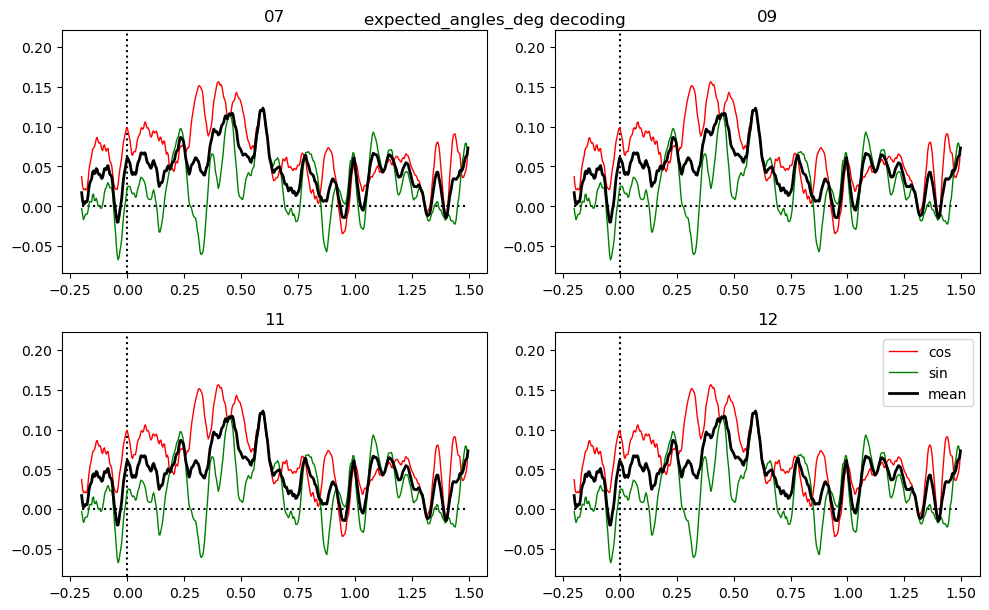

In [ ]:
###### OPEN AND PLOT
times = get_timearray(SW, tmin, tmax)
idx_zero = np.abs(times - 0).argmin()
idx_tmin = np.abs(times - tmin).argmin()
idx_tmax = np.abs(times - tmax).argmin()


plt.figure(figsize = (10,9))
for i, sub in enumerate(SUBJS):
    alldat =[]

    plt.subplot(int(len(SUBJS)/2)+1, 2, i+1)
    
    datCos = open_decodingresults(derivative_root + f"sub-{sub}/" + f"{condition}_Cos_{sub}.pkl", SW)
    datSin = open_decodingresults(derivative_root + f"sub-{sub}/" + f"{condition}_Sin_{sub}.pkl", SW)
    border_max = max(np.array(datSin)[0,0,:])+0.1
    border_min = min(np.array(datCos)[0,0,:])-0.05
    plt.plot([times[0],times[-1]],[0,0], 'k:')
    plt.plot([0,0],[border_min,border_max], 'k:')
    
    dat = np.mean([datCos,datSin],0)
    alldat.append(np.array(dat).flatten())
    plt.plot(times, np.array(datCos)[0,0,:], 'red', linewidth=1, label = "cos")
    plt.plot(times, np.array(datSin)[0,0,:], 'green', linewidth=1, label = "sin")
    plt.plot(times, np.array(dat)[0,0,:], 'black', linewidth=2, label = "mean")
    plt.ylim([border_min,border_max])
    plt.title(sub)
plt.tight_layout()
plt.legend()
plt.suptitle(f"{condition} decoding")
plt.show()





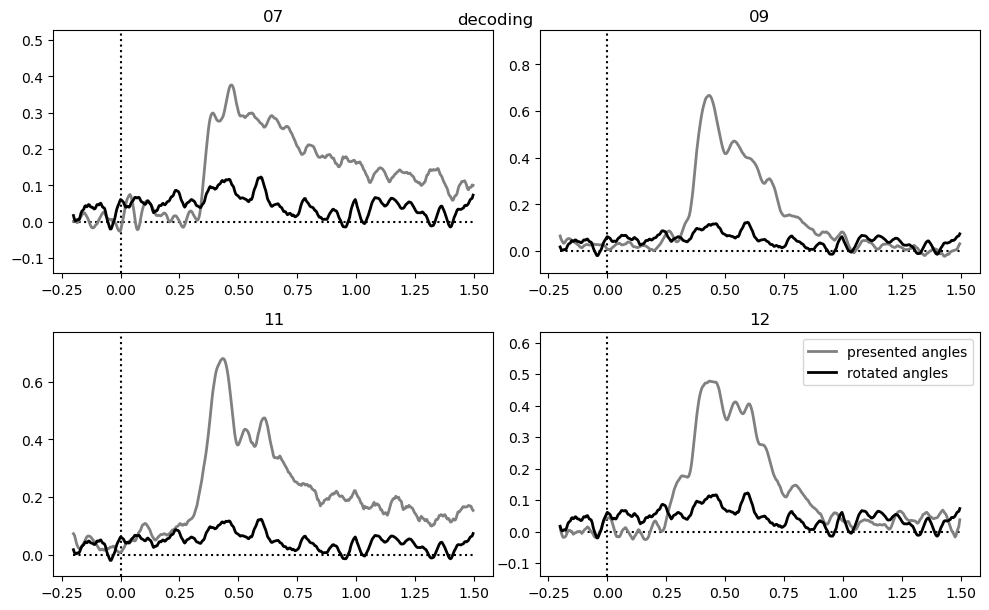

In [16]:
alldatres =[]
alldatrot = []

plt.figure(figsize = (10,9))
for i, sub in enumerate(SUBJS):
    plt.subplot(int(len(SUBJS)/2)+1, 2, i+1)
    
    datCospres = open_decodingresults(derivative_root + f"sub-{sub}/" + f"presented_angles_Cos_{sub}.pkl", SW)
    datSinpres = open_decodingresults(derivative_root + f"sub-{sub}/" + f"presented_angles_Sin_{sub}.pkl", SW)

    datCosrot = open_decodingresults(derivative_root + f"sub-{sub}/" + f"expected_angles_deg_Cos_{sub}.pkl", SW)
    datSinrot = open_decodingresults(derivative_root + f"sub-{sub}/" + f"expected_angles_deg_Sin_{sub}.pkl", SW)
    
    border_max = max(np.array(datSinpres)[0,0,:])+0.1
    border_min = min(np.array(datCospres)[0,0,:])-0.05
    plt.plot([times[0],times[-1]],[0,0], 'k:')
    plt.plot([0,0],[border_min,border_max], 'k:')
    
    datres = np.mean([datCospres,datSinpres],0)
    alldatres.append(np.array(datres).flatten())

    datrot = np.mean([datCosrot,datSinrot],0)
    alldatrot.append(np.array(datrot).flatten())
 
    # plt.plot(times, np.array(datCosrot)[0,0,:], 'red', linewidth=1, label = "cos")
    # plt.plot(times, np.array(datSinrot)[0,0,:], 'green', linewidth=1, label = "sin")
    
    # plt.plot(times, np.array(datCospres)[0,0,:], 'red', linewidth=1, label = "cos")
    # plt.plot(times, np.array(datSinpres)[0,0,:], 'green', linewidth=1, label = "sin")
    
    plt.plot(times, np.array(datres)[0,0,:], 'grey', linewidth=2, label = "presented angles")
    plt.plot(times, np.array(datrot)[0,0,:], 'black', linewidth=2, label = "rotated angles")
    
    plt.ylim([border_min,border_max])
    plt.title(sub)
plt.tight_layout()
plt.legend()
plt.suptitle(f"decoding")
plt.show()